# Laptop Price Prediction — End-to-End ML Analysis

**A reproducible, end-to-end regression case study.**

> This notebook rebuilds the project's machine-learning pipeline from scratch with a
> strict focus on reproducibility, leakage prevention, honest evaluation, and a single
> deployable artifact: one scikit-learn `Pipeline` that contains *all* preprocessing
> plus the final model, so a downstream application never has to re-implement
> feature engineering by hand.

---


## 1. Problem Statement

**Goal.** Predict the retail price of a laptop (in Indian Rupees, INR) from its
specifications — brand, type, screen, CPU, RAM, storage, GPU, OS and weight.

**Why this is hard.** Price depends on interacting, partly redundant specifications
(screen size <-> resolution <-> panel type; storage type <-> capacity), the
relationship is non-linear, and the price distribution is right-skewed (a few
premium laptops cost 3-5x the median).

**Approach.**

1. Audit and clean the raw data, documenting every decision.
2. Engineer structured, interpretable features from raw strings (`ScreenResolution`,
   `Memory`, `Cpu`, `Gpu`) instead of opaque label encodings.
3. Split into train/test **before** any learned preprocessing to avoid leakage.
4. Compare a dummy baseline against four standard regressors using 5-fold
   cross-validation on the training set only -- for **both** a raw price target and a
   `log1p(price)` target.
5. Tune the winning configuration lightly, then evaluate **exactly once** on the
   untouched test set.
6. Analyse errors and feature importances, then persist one complete pipeline
   (`models/laptop_price_pipeline.pkl`) plus JSON metadata.

**Reading metric values.** All price metrics (MAE, RMSE, MAPE) are reported on the
original rupee scale, even when the model was trained on `log1p` prices. R2 is a
coefficient of determination -- it is never referred to as "accuracy".


### Environment and global configuration

In [1]:
import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    make_scorer,
)
from sklearn.inspection import permutation_importance

# --- versions (required for reproducibility) ---
print("Python          :", sys.version.split()[0], f"({platform.platform()})")
print("pandas          :", pd.__version__)
print("numpy           :", np.__version__)
print("scikit-learn    :", sklearn.__version__)
print("matplotlib      :", matplotlib.__version__)
print("seaborn         :", sns.__version__)

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

# --- global configuration (all random seeds are explicit) ---
RANDOM_STATE = 42   # documented choice: fixed once, used for split + CV + models
TEST_SIZE    = 0.20 # 20% held out for the final, one-shot evaluation
N_SPLITS     = 5    # 5-fold CV for model comparison on the training set

# --- locate project root robustly (works from repo root or from notebooks/) ---
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "laptop_data.csv").exists() else cwd.parent
DATA_PATH  = PROJECT_ROOT / "laptop_data.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

print("\nData   :", DATA_PATH)
print("Models :", MODELS_DIR)
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

Python          : 3.12.7 (Windows-11-10.0.26300-SP0)
pandas          : 2.2.2
numpy           : 1.26.4
scikit-learn    : 1.8.0
matplotlib      : 3.10.8
seaborn         : 0.13.2

Data   : C:\Users\Farha Sultana\OneDrive\Desktop\LaptopPricePrediction\laptop_data.csv
Models : C:\Users\Farha Sultana\OneDrive\Desktop\LaptopPricePrediction\models


## 2. Dataset Overview

The dataset is the well-known laptop specification dataset (~1,300 rows). We verify
its actual shape rather than assuming it, inspect schema and dtypes, and treat the
unnamed CSV index column purely as an identifier -- never as a predictive feature.


In [2]:
df_raw = pd.read_csv(DATA_PATH)

print("Shape :", df_raw.shape)   # verified, not hardcoded
print("Columns:", df_raw.columns.tolist())
print()
print(df_raw.dtypes.to_string())
print("\nFirst rows:")
df_raw.head()

Shape : (1303, 12)
Columns: ['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']

Unnamed: 0            int64
Company              object
TypeName             object
Inches              float64
ScreenResolution     object
Cpu                  object
Ram                  object
Memory               object
Gpu                  object
OpSys                object
Weight               object
Price               float64

First rows:


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


## 3. Data Quality Assessment

Checks performed: missing values, duplicate records, per-column cardinality, and
numeric summary statistics.

**Duplicate handling policy.** The CSV ships an `Unnamed: 0` index column, so two
kinds of duplicates exist: *exact* duplicates (all 12 columns identical) and
*duplicates ignoring the index* (all real fields identical). The latter are true
duplicate records of the same laptop listing. They are removed in Section 4 so an
identical row cannot appear in both the train and test sets (which would leak
information and optimistically bias metrics).


In [3]:
# Missing values
missing = df_raw.isna().sum()
print("Total missing values:", int(missing.sum()))
if missing.any():
    print(missing[missing > 0])
else:
    print("  (no missing values in any column)")

# Duplicates: exact vs ignoring the identifier column
exact_dupes = int(df_raw.duplicated().sum())
idx_col = [c for c in df_raw.columns if c.startswith("Unnamed")]
dupes_ignoring_id = int(df_raw.drop(columns=idx_col).duplicated().sum())
print(f"\nExact duplicate rows (all 12 cols) : {exact_dupes}")
print(f"Duplicate rows ignoring identifier  : {dupes_ignoring_id}")

# Cardinality of categorical columns
cat_cols = df_raw.select_dtypes(include="object").columns
print("\nCategorical cardinality:")
for c in cat_cols:
    print(f"  {c:20s} {df_raw[c].nunique():4d} unique   e.g. {df_raw[c].iloc[0]!r}")

Total missing values: 0
  (no missing values in any column)

Exact duplicate rows (all 12 cols) : 0
Duplicate rows ignoring identifier  : 29

Categorical cardinality:
  Company                19 unique   e.g. 'Apple'
  TypeName                6 unique   e.g. 'Ultrabook'
  ScreenResolution       40 unique   e.g. 'IPS Panel Retina Display 2560x1600'
  Cpu                   118 unique   e.g. 'Intel Core i5 2.3GHz'
  Ram                     9 unique   e.g. '8GB'
  Memory                 39 unique   e.g. '128GB SSD'
  Gpu                   110 unique   e.g. 'Intel Iris Plus Graphics 640'
  OpSys                   9 unique   e.g. 'macOS'
  Weight                179 unique   e.g. '1.37kg'


In [4]:
# Numeric summary statistics (identifier excluded)
describe_cols = [c for c in df_raw.columns if c != "Unnamed: 0"]
df_raw[describe_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Inches,1303.0,15.017191,1.426304,10.10,14.00,15.60,15.6000,18.40
Price,1303.0,59870.042910,37243.201786,9270.72,31914.72,52054.56,79274.2464,324954.72


Target : Price (INR)
count  :  1303
min    :    9270.72
median :   52054.56
mean   :   59870.04
max    :  324954.72
std    :   37243.20
skew   :      1.521   (right-skewed if > 0)
max / median ratio: 6.24x


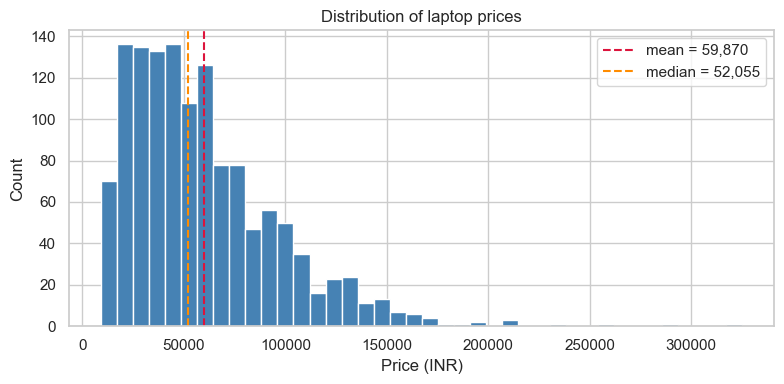

Observation: the target is clearly right-skewed -> motivates the log1p target experiment (Sections 5 and 11).


In [5]:
# Target distribution
price = df_raw["Price"]
print("Target : Price (INR)")
print(f"count  : {price.count():5d}")
print(f"min    : {price.min():10.2f}")
print(f"median : {price.median():10.2f}")
print(f"mean   : {price.mean():10.2f}")
print(f"max    : {price.max():10.2f}")
print(f"std    : {price.std():10.2f}")
print(f"skew   : {price.skew():10.3f}   (right-skewed if > 0)")
print(f"max / median ratio: {price.max() / price.median():.2f}x")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(price, bins=40, color="steelblue", edgecolor="white")
ax.axvline(price.mean(), color="crimson", ls="--", label=f"mean = {price.mean():,.0f}")
ax.axvline(price.median(), color="darkorange", ls="--", label=f"median = {price.median():,.0f}")
ax.set_title("Distribution of laptop prices")
ax.set_xlabel("Price (INR)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

print("Observation: the target is clearly right-skewed -> motivates the log1p "
      "target experiment (Sections 5 and 11).")

## 4. Data Cleaning

Every cleaning decision, with justification:

| # | Decision | Justification |
|---|----------|---------------|
| 1 | Drop `Unnamed: 0` | It is a CSV row index, not a laptop attribute. The old pipeline leaked it into the model as a feature. |
| 2 | Remove duplicate records (identical on all real fields) | The dataset contains rows identical in *every* real field including price -- duplicated listings that add zero information and could straddle the train/test split, leaking across it. Counts reported below. |
| 3 | Parse `Ram` (`"8GB"`) to integer `RAM_GB` | Unit-bearing text stored as object; models need numbers. |
| 4 | Parse `Weight` (`"1.37kg"`) to float `Weight_kg` | Same as above. |
| 5 | **Keep** all remaining rows | Range checks (below) show no impossible values: screen sizes 10.1-18.4 in, weights 0.69-4.7 kg (heavy ones are gaming laptops), prices 9k-325k INR are plausible premium models. No arbitrary outlier removal. |
| 6 | Preserve raw categorical strings | `Company`, `TypeName`, `OpSys` etc. stay as categories; encoding happens later *inside* the pipeline, fit on training data only. |

The original CSV file is never modified on disk.


In [6]:
df = df_raw.copy()

# --- 1. identifier column ---
assert idx_col == ["Unnamed: 0"], f"unexpected identifier columns: {idx_col}"
df = df.drop(columns=idx_col)
print(f"Rows after dropping identifier column : {len(df)}")

# --- 2. duplicate records (reported before / removed / after) ---
n_before = len(df)
df = df.drop_duplicates()
n_after = len(df)
print("Duplicate-removal report:")
print(f"  rows before : {n_before}")
print(f"  removed     : {n_before - n_after}")
print(f"  rows after  : {n_after}")
assert n_before - n_after == dupes_ignoring_id, "duplicate count mismatch"

# --- 3 & 4. unit-bearing numerics ---
assert df["Ram"].dtype == object and df["Weight"].dtype == object
df["RAM_GB"] = df["Ram"].str.replace("GB", "", regex=False).astype(int)
df["Weight_kg"] = df["Weight"].str.replace("kg", "", regex=False).astype(float)

# --- 5. unusual-value inspection (no deletions without justification) ---
print("\nRAM values   :", sorted(df["RAM_GB"].unique()))
print(f"Weight range : {df['Weight_kg'].min()} - {df['Weight_kg'].max()} kg")
print(f"Inches range : {df['Inches'].min()} - {df['Inches'].max()}")
print(f"Price range  : {df['Price'].min():,.0f} - {df['Price'].max():,.0f} INR")
print("\nWeights above 4 kg (all gaming laptops - legitimate, retained):")
print(df.loc[df["Weight_kg"] > 4, ["Company", "TypeName", "Weight_kg"]]
      .value_counts().head(8).to_string())

df = df.reset_index(drop=True)
print(f"\nClean dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Rows after dropping identifier column : 1303
Duplicate-removal report:
  rows before : 1303
  removed     : 29
  rows after  : 1274

RAM values   : [2, 4, 6, 8, 12, 16, 24, 32, 64]
Weight range : 0.69 - 4.7 kg
Inches range : 10.1 - 18.4
Price range  : 9,271 - 324,955 INR

Weights above 4 kg (all gaming laptops - legitimate, retained):
Company  TypeName  Weight_kg
Dell     Gaming    4.42         10
Asus     Gaming    4.30          4
Dell     Gaming    4.36          4
Lenovo   Gaming    4.60          4
Acer     Gaming    4.20          3
MSI      Gaming    4.14          3
Asus     Gaming    4.33          1
                   4.70          1

Clean dataset: 1274 rows x 13 columns


**Cleaning summary**

* Rows before: **1,303** -> duplicates removed: **29** -> rows after: **1,274**.
* The 29 removed rows were identical on every real field (including price) once the
  CSV index was excluded -- duplicated listings, not distinct laptops.
* No laptop was removed for being an "outlier": every extreme value inspected
  (4.4-4.7 kg gaming laptops, ~325k INR premium models) is a legitimate product.
* Raw categorical values are untouched -- no encoding has happened yet.


## 5. Feature Engineering

Raw free-text fields are converted into structured, interpretable features. Design
principle: **robust and interpretable over clever**. No manually hardcoded
`LabelEncoder` dictionaries (the failure mode of the previous implementation) --
categorical features stay as *categories* and are one-hot encoded later inside the
pipeline.

### Screen resolution -> display features

`ScreenResolution` mixes four pieces of information in one string, e.g.
`"IPS Panel Retina Display 2560x1600"`, `"Full HD / Touchscreen 1920x1080"`:

| Feature | Meaning |
|---|---|
| `Resolution_X`, `Resolution_Y` | pixel width/height (regex `\d+x\d+`, verified on 100% of rows) |
| `Touchscreen` | 1/0 flag (`'Touchscreen' in string`) |
| `IPS` | 1/0 flag (`'IPS' in string`) |
| `Pixels` | total pixel count `X * Y` |
| `PPI` | pixels per inch `sqrt(X^2 + Y^2) / Inches` -- screen sharpness |

### Memory -> storage features

`Memory` holds combinations such as `"128GB SSD +  1TB HDD"` or `"256GB SSD +  1.0TB Hybrid"`.
The parser splits on `+`, extracts `(<number>) (TB|GB)` **per component**, converts
TB -> 1000 GB (decimal convention, consistent with how storage is marketed and with
the old pipeline), and accumulates four capacity columns. This guarantees no
storage information is silently lost. (The previous implementation contained a bug
where `"1.0TB"` parsed as 10,000 GB -- the parser below is validated by assertion.)

### CPU / GPU -> brand, tier/series, frequency

Instead of encoding 118 raw CPU strings and 110 GPU strings as arbitrary integers:

* `CPU_Brand`: Intel / AMD / Samsung (from the first token).
* `CPU_Tier`: `Core i3/i5/i7/i9`, `Celeron`, `Pentium`, `Atom`, `Intel Other`,
  `AMD Ryzen`, `AMD Other`, `Other` -- ordered by evidence in the data.
* `CPU_Freq_GHz`: clock speed parsed from `"2.3GHz"` (present in every row).
* `GPU_Brand`: Intel / Nvidia / AMD / ARM.
* `GPU_Series`: `GeForce`, `Quadro`, `Radeon`, `FirePro`, `Iris`, `UHD`, `HD`,
  `Mali`, `Other` (checked in priority order because e.g. `"UHD"` contains `"HD"`).

*Deliberately not engineered:* core count (`Dual/Quad Core` appears in only ~118 of
1,274 rows -- too sparse to be a reliable feature).


In [7]:
import re

# ---- Screen resolution -----------------------------------------------------
res = df["ScreenResolution"].str.extract(r"(\d+)x(\d+)")
assert res.notna().all().all(), "resolution regex failed on some rows"
df["Resolution_X"] = res[0].astype(int)
df["Resolution_Y"] = res[1].astype(int)
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS").astype(int)
df["Pixels"] = df["Resolution_X"] * df["Resolution_Y"]
diag_in = np.hypot(df["Resolution_X"], df["Resolution_Y"])
df["PPI"] = diag_in / df["Inches"]

print(f"Resolution parsed for {len(df)}/{len(df)} rows")
print(f"Touchscreen: {df['Touchscreen'].sum()}   IPS: {df['IPS'].sum()}")
print(f"PPI range  : {df['PPI'].min():.1f} - {df['PPI'].max():.1f}")

Resolution parsed for 1274/1274 rows
Touchscreen: 188   IPS: 357
PPI range  : 90.6 - 352.5


In [8]:
# ---- Memory ----------------------------------------------------------------
def parse_memory(mem: str) -> dict:
    """Parse '128GB SSD +  1TB HDD' into per-type GB capacities. No info lost."""
    caps = {"SSD_GB": 0.0, "HDD_GB": 0.0, "Flash_GB": 0.0, "Hybrid_GB": 0.0}
    for part in str(mem).split("+"):
        part = part.strip()
        m = re.match(r"([\d.]+)\s*(TB|GB)", part)
        if not m:
            continue
        value = float(m.group(1)) * (1000.0 if m.group(2) == "TB" else 1.0)
        if "SSD" in part:
            caps["SSD_GB"] += value
        elif "HDD" in part:
            caps["HDD_GB"] += value
        elif "Flash" in part:
            caps["Flash_GB"] += value
        elif "Hybrid" in part:
            caps["Hybrid_GB"] += value
    return caps

mem_parsed = df["Memory"].apply(parse_memory).apply(pd.Series)
df = pd.concat([df, mem_parsed], axis=1)

# Validation: every row must have >0 GB of *some* storage
total_storage = mem_parsed.sum(axis=1)
assert (total_storage > 0).all(), "some Memory values failed to parse"
print(f"Memory parsed for {len(df)}/{len(df)} rows (all with >0 GB)")
print("\nStorage distributions (GB):")
print(mem_parsed.describe().T[["min", "50%", "max"]].to_string())
print("\nExample combinations:")
ex = pd.concat([df["Memory"], mem_parsed], axis=1)
print(ex[ex["Memory"].str.contains(r"\+")].drop_duplicates("Memory").head(8).to_string(index=False))

Memory parsed for 1274/1274 rows (all with >0 GB)

Storage distributions (GB):
           min    50%     max
SSD_GB     0.0  256.0  1024.0
HDD_GB     0.0    0.0  2000.0
Flash_GB   0.0    0.0   512.0
Hybrid_GB  0.0    0.0  1000.0

Example combinations:
                Memory  SSD_GB  HDD_GB  Flash_GB  Hybrid_GB
  128GB SSD +  1TB HDD   128.0  1000.0       0.0        0.0
256GB SSD +  256GB SSD   512.0     0.0       0.0        0.0
  256GB SSD +  1TB HDD   256.0  1000.0       0.0        0.0
  256GB SSD +  2TB HDD   256.0  2000.0       0.0        0.0
  512GB SSD +  1TB HDD   512.0  1000.0       0.0        0.0
256GB SSD +  500GB HDD   256.0   500.0       0.0        0.0
  128GB SSD +  2TB HDD   128.0  2000.0       0.0        0.0
512GB SSD +  512GB SSD  1024.0     0.0       0.0        0.0


In [9]:
# ---- CPU -------------------------------------------------------------------
def cpu_brand(cpu: str) -> str:
    return cpu.split()[0]                      # Intel / AMD / Samsung

def cpu_tier(cpu: str) -> str:
    for tier in ("Core i3", "Core i5", "Core i7", "Core i9"):
        if tier in cpu:
            return tier
    brand = cpu_brand(cpu)
    if brand == "Intel":
        for tier in ("Celeron", "Pentium", "Atom"):
            if tier in cpu:
                return tier
        return "Intel Other"                   # Xeon, older Core, etc.
    if brand == "AMD":
        return "AMD Ryzen" if "Ryzen" in cpu else "AMD Other"
    return "Other"

df["CPU_Brand"] = df["Cpu"].apply(cpu_brand)
df["CPU_Tier"] = df["Cpu"].apply(cpu_tier)

freq = df["Cpu"].str.extract(r"([\d.]+)\s*GHz")[0]
assert freq.notna().all(), "CPU frequency missing on some rows"
df["CPU_Freq_GHz"] = freq.astype(float)

print("CPU_Brand:"); print(df["CPU_Brand"].value_counts().to_string())
print("\nCPU_Tier:"); print(df["CPU_Tier"].value_counts().to_string())
print(f"\nCPU_Freq_GHz range: {df['CPU_Freq_GHz'].min()} - {df['CPU_Freq_GHz'].max()}")

CPU_Brand:
CPU_Brand
Intel      1213
AMD          60
Samsung       1

CPU_Tier:
CPU_Tier
Core i7        515
Core i5        423
Core i3        134
Celeron         77
AMD Other       56
Pentium         30
Intel Other     21
Atom            13
AMD Ryzen        4
Other            1

CPU_Freq_GHz range: 0.9 - 3.6


In [10]:
# ---- GPU -------------------------------------------------------------------
def gpu_brand(gpu: str) -> str:
    return gpu.split()[0]                      # Intel / Nvidia / AMD / ARM

def gpu_series(gpu: str) -> str:
    # Priority order matters: 'UHD' contains 'HD'; check Radeon before HD, etc.
    if "GeForce" in gpu or gpu.startswith("GTX"):
        return "GeForce"
    if "Quadro" in gpu:
        return "Quadro"
    if "Radeon" in gpu:
        return "Radeon"
    if "FirePro" in gpu:
        return "FirePro"
    if "Iris" in gpu:
        return "Iris"
    if "UHD" in gpu:
        return "UHD"
    if "HD" in gpu:
        return "HD"
    if "Mali" in gpu:
        return "Mali"
    return "Other"

df["GPU_Brand"] = df["Gpu"].apply(gpu_brand)
df["GPU_Series"] = df["Gpu"].apply(gpu_series)

print("GPU_Brand:"); print(df["GPU_Brand"].value_counts().to_string())
print("\nGPU_Series:"); print(df["GPU_Series"].value_counts().to_string())
print("\nBrand x Series sanity check:")
print(pd.crosstab(df["GPU_Brand"], df["GPU_Series"]).to_string())

GPU_Brand:
GPU_Brand
Intel     703
Nvidia    396
AMD       174
ARM         1

GPU_Series:
GPU_Series
HD         620
GeForce    364
Radeon     167
UHD         68
Quadro      31
Iris        14
FirePro      5
Other        4
Mali         1

Brand x Series sanity check:
GPU_Series  FirePro  GeForce   HD  Iris  Mali  Other  Quadro  Radeon  UHD
GPU_Brand                                                                
AMD               5        0    0     0     0      2       0     167    0
ARM               0        0    0     0     1      0       0       0    0
Intel             0        0  620    14     0      1       0       0   68
Nvidia            0      364    0     0     0      1      31       0    0


In [11]:
# ---- Final engineered feature frame ---------------------------------------
print("Columns now present:")
for c in df.columns:
    print(f"  {c:20s} {str(df[c].dtype):10s} {df[c].nunique():5d} unique")
print(f"\nShape: {df.shape}")
assert df.isna().sum().sum() == 0, "NaNs introduced during feature engineering"
print("No NaNs after feature engineering.")
df.head()

Columns now present:
  Company              object        19 unique
  TypeName             object         6 unique
  Inches               float64       18 unique
  ScreenResolution     object        40 unique
  Cpu                  object       118 unique
  Ram                  object         9 unique
  Memory               object        39 unique
  Gpu                  object       110 unique
  OpSys                object         9 unique
  Weight               object       179 unique
  Price                float64      791 unique
  RAM_GB               int32          9 unique
  Weight_kg            float64      171 unique
  Resolution_X         int32         13 unique
  Resolution_Y         int32         10 unique
  Touchscreen          int32          2 unique
  IPS                  int32          2 unique
  Pixels               int32         15 unique
  PPI                  float64       39 unique
  SSD_GB               float64       13 unique
  HDD_GB               float64        6

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,...,PPI,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,CPU_Brand,CPU_Tier,CPU_Freq_GHz,GPU_Brand,GPU_Series
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,...,226.983005,128.0,0.0,0.0,0.0,Intel,Core i5,2.3,Intel,Iris
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,...,127.677940,0.0,0.0,128.0,0.0,Intel,Core i5,1.8,Intel,HD
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,...,141.211998,256.0,0.0,0.0,0.0,Intel,Core i5,2.5,Intel,HD
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,...,220.534624,512.0,0.0,0.0,0.0,Intel,Core i7,2.7,AMD,Radeon
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,...,226.983005,256.0,0.0,0.0,0.0,Intel,Core i5,3.1,Intel,Iris


## 6. Exploratory Data Analysis

A focused EDA: how does price relate to the most important specifications? The
purpose is to (a) build intuition for the error analysis later and (b) verify that
the engineered features carry signal.


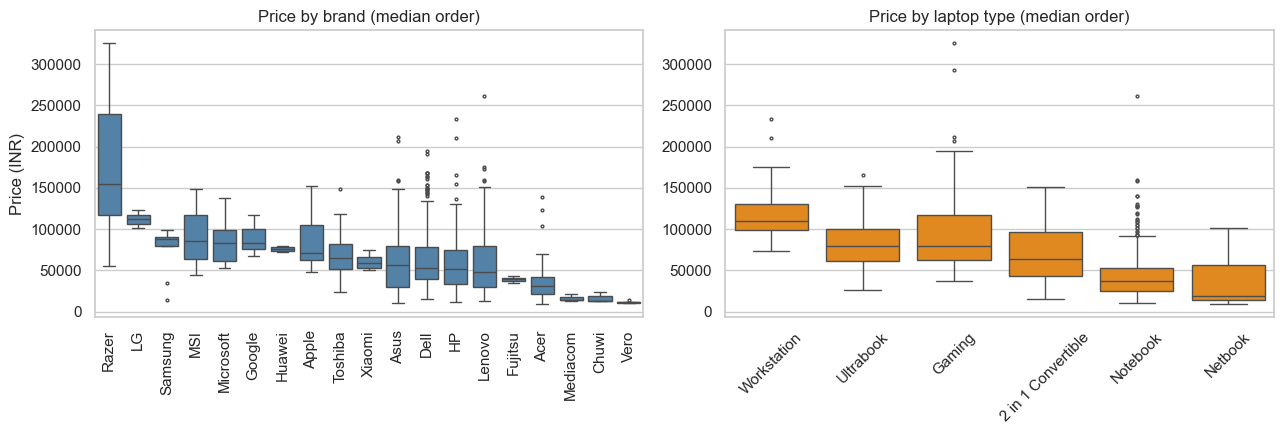

Expected signal: Razer/MSI/Apple skew expensive; Workstation/Gaming > Notebook/Netbook.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Price by company
order = df.groupby("Company")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Company", y="Price", order=order, ax=axes[0],
            color="steelblue", fliersize=2)
axes[0].set_title("Price by brand (median order)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Price (INR)")
axes[0].tick_params(axis="x", rotation=90)

# Price by laptop type
order2 = df.groupby("TypeName")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="TypeName", y="Price", order=order2, ax=axes[1],
            color="darkorange", fliersize=2)
axes[1].set_title("Price by laptop type (median order)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print("Expected signal: Razer/MSI/Apple skew expensive; Workstation/Gaming > Notebook/Netbook.")

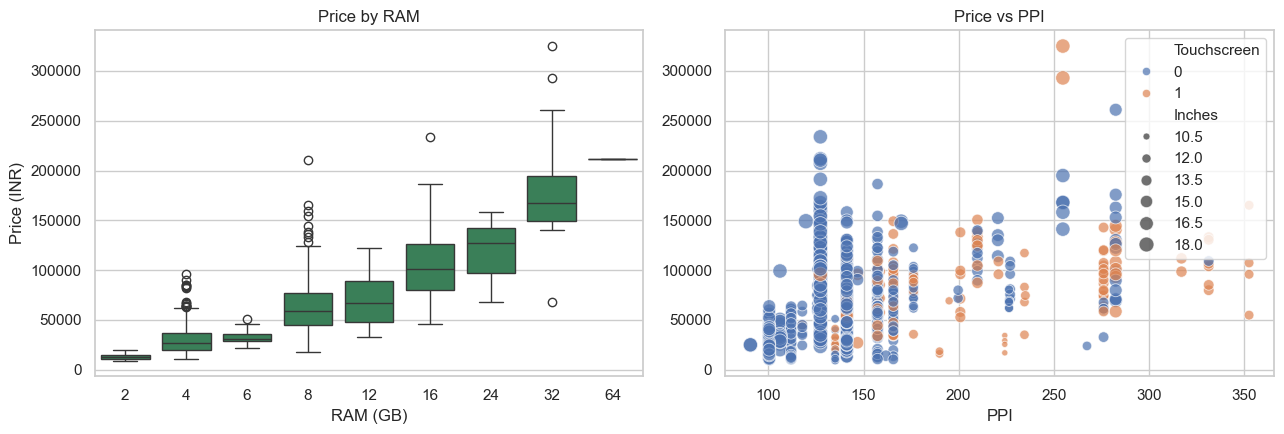

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=df, x="RAM_GB", y="Price", ax=axes[0], color="seagreen")
axes[0].set_title("Price by RAM")
axes[0].set_xlabel("RAM (GB)")
axes[0].set_ylabel("Price (INR)")

sns.scatterplot(data=df, x="PPI", y="Price", hue="Touchscreen",
                size="Inches", sizes=(20, 120), ax=axes[1], alpha=0.7)
axes[1].set_title("Price vs PPI")
axes[1].set_xlabel("PPI")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

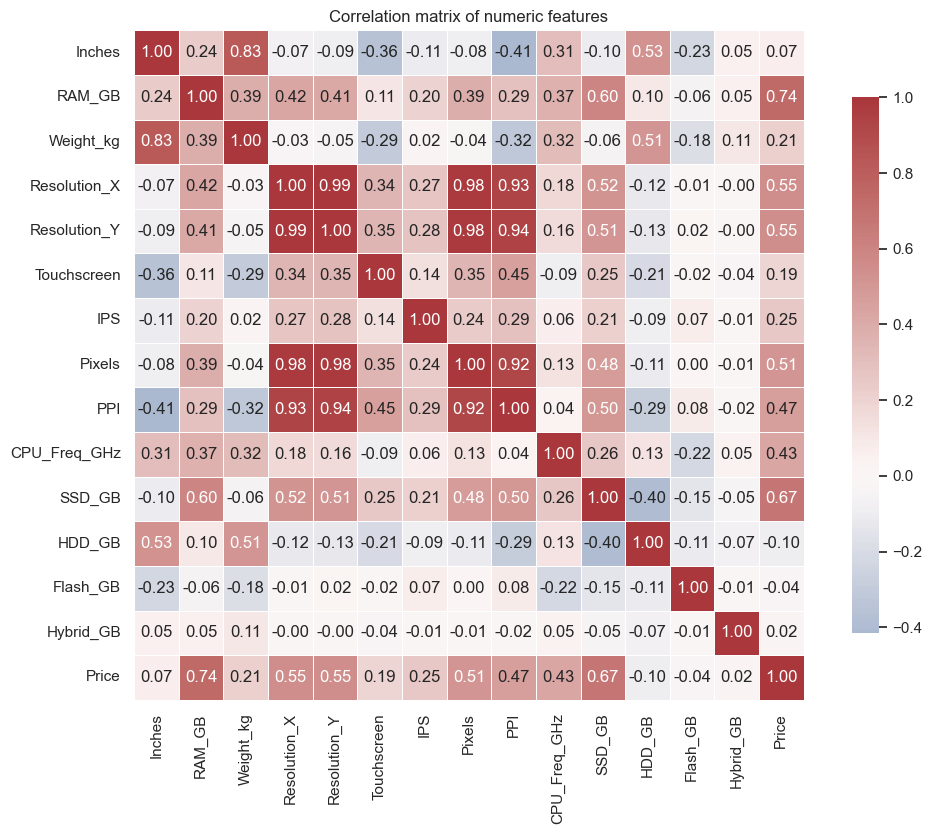

Correlation with Price:
RAM_GB          0.740106
SSD_GB          0.669957
Resolution_X    0.552074
Resolution_Y    0.548111
Pixels          0.511428
PPI             0.469539
CPU_Freq_GHz    0.428178
IPS             0.250358
Weight_kg       0.212192
Touchscreen     0.188631
Inches          0.066990
Hybrid_GB       0.022533
Flash_GB       -0.037176
HDD_GB         -0.098011

Note: RAM/SSD/CPU-frequency correlate positively with price; HDD correlates negatively (cheap bulk-storage notebooks).


In [14]:
# Correlation structure of engineered numeric features
num_cols = ["Inches", "RAM_GB", "Weight_kg", "Resolution_X", "Resolution_Y",
            "Touchscreen", "IPS", "Pixels", "PPI", "CPU_Freq_GHz",
            "SSD_GB", "HDD_GB", "Flash_GB", "Hybrid_GB", "Price"]

corr = df[num_cols].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.show()

top = corr["Price"].drop("Price").sort_values(ascending=False)
print("Correlation with Price:")
print(top.to_string())
print("\nNote: RAM/SSD/CPU-frequency correlate positively with price; HDD correlates "
      "negatively (cheap bulk-storage notebooks).")

## 7. Train/Test Split

* **20% test**, **80% train**, `random_state=42`.

*Why 42?* It is a fixed, documented, widely used convention -- chosen once and used
for the split, cross-validation folds and every model so the whole experiment is
bit-for-bit reproducible.

*Order matters:* cleaning and feature engineering (which learn nothing from data)
happen first, then the split, and only then is preprocessing fit -- on the training
partition only. The test set is **never** looked at again until Section 13.


In [15]:
FEATURE_COLS = [
    # categorical
    "Company", "TypeName", "OpSys",
    "CPU_Brand", "CPU_Tier", "GPU_Brand", "GPU_Series",
    # numeric
    "Inches", "RAM_GB", "Weight_kg",
    "Resolution_X", "Resolution_Y", "Touchscreen", "IPS",
    "Pixels", "PPI", "CPU_Freq_GHz",
    "SSD_GB", "HDD_GB", "Flash_GB", "Hybrid_GB",
]
TARGET = "Price"

X = df[FEATURE_COLS].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} rows  ({X_train.shape[0]/len(X):.0%})")
print(f"Test : {X_test.shape[0]} rows  ({X_test.shape[0]/len(X):.0%})")
print(f"Features: {len(FEATURE_COLS)} "
      f"({sum(c in df.select_dtypes('object').columns for c in FEATURE_COLS)} categorical, "
      f"{sum(c not in df.select_dtypes('object').columns for c in FEATURE_COLS)} numeric)")
print(f"\nPrice mean  train={y_train.mean():,.0f}  test={y_test.mean():,.0f}  "
      f"(split is representative)")
print(f"Price median train={y_train.median():,.0f}  test={y_test.median():,.0f}")

Train: 1019 rows  (80%)
Test : 255 rows  (20%)
Features: 21 (7 categorical, 14 numeric)

Price mean  train=59,840  test=63,155  (split is representative)
Price median train=52,161  test=53,807


## 8. Preprocessing Pipeline

Everything that *learns* from data lives inside one `ColumnTransformer`, which is
embedded in the model `Pipeline`:

* **Categorical** (7 columns) -> `OneHotEncoder(handle_unknown="ignore")`.
  One-hot (not ordinal/label encoding) because the categories are unordered;
  `handle_unknown="ignore"` makes the artifact robust to categories never seen in
  training. No dictionary is hardcoded anywhere -- the encoder object itself *is*
  the persisted encoding, which is exactly what the old `app.py` got wrong.
* **Numeric** (14 columns) -> `StandardScaler`. Harmless for tree models, and
  required for fair play by `LinearRegression`.

Because the `ColumnTransformer` sits *inside* the `Pipeline`, `.fit()` is only ever
called on training folds -- preprocessing cannot see the test data.


In [16]:
CATEGORICAL = ["Company", "TypeName", "OpSys",
               "CPU_Brand", "CPU_Tier", "GPU_Brand", "GPU_Series"]
NUMERIC = [c for c in FEATURE_COLS if c not in CATEGORICAL]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", StandardScaler(), NUMERIC),
    ],
    remainder="drop",
)

def make_pipeline(estimator) -> Pipeline:
    """Fresh pipeline (preprocessing + estimator) for a given model."""
    return Pipeline([("preprocess", preprocessor), ("model", estimator)])

print("Categorical features:", CATEGORICAL)
print("Numeric features    :", NUMERIC)

# Shape check of the transformed matrix (fit on train only, for display)
probe = make_pipeline(LinearRegression()).fit(X_train, y_train)
ohe = probe.named_steps["preprocess"].named_transformers_["cat"]
print(f"\nTransformed shape on train: {probe.named_steps['preprocess'].transform(X_train).shape}")
print(f"One-hot columns learned   : {ohe.get_feature_names_out().size}")

Categorical features: ['Company', 'TypeName', 'OpSys', 'CPU_Brand', 'CPU_Tier', 'GPU_Brand', 'GPU_Series']
Numeric features    : ['Inches', 'RAM_GB', 'Weight_kg', 'Resolution_X', 'Resolution_Y', 'Touchscreen', 'IPS', 'Pixels', 'PPI', 'CPU_Freq_GHz', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']

Transformed shape on train: (1019, 74)
One-hot columns learned   : 60


## 9. Baseline Model

`DummyRegressor(strategy="mean")` predicts the training-set mean for every laptop.
It defines the bar any real model must clear -- if we cannot beat it, the features
carry no usable signal. Evaluated with the *same* 5-fold CV framework used for the
candidate models below (its numbers appear in the Section 11 table).


## 10. Model Comparison

Four standard tabular regressors plus the baseline:

| Model | Why include it |
|---|---|
| `LinearRegression` | fast, interpretable lower bound (learns linear price rules) |
| `RandomForestRegressor` | robust bagged trees, tolerates feature interactions |
| `GradientBoostingRegressor` | sequential boosting, usually strong on tabular data |
| `ExtraTreesRegressor` | extremely-randomized trees, often beats RF on small data |

All are seeded with `random_state=42`; sensible initial hyperparameters only --
this stage establishes a reliable comparison, not a tuned winner.


## 11. Cross-Validation

5-fold K-fold CV (`shuffle=True`, `random_state=42`) on the **training set only**.
Two target variants are evaluated with the *identical* framework:

* **(A) raw price** -- the model regresses INR directly;
* **(B) log1p(price)** -- the model regresses `log1p(INR)`; predictions are
  converted back with `expm1` *before* computing metrics, so every number below is
  a comparable rupee-scale error.

Reported per model: MAE, RMSE, R2, MAPE (mean over 5 folds; std shown too).
The test set is **not touched** in this section.


In [17]:
def metrics_block(y_true, y_pred) -> dict:
    """All metrics on the original rupee scale."""
    y_pred = np.clip(y_pred, 0, None)          # prices cannot be negative
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }

def cv_evaluate(name, factory, target: str, X_, y_) -> dict:
    """Manual 5-fold CV so log-target predictions can be expm1'd before metrics."""
    assert target in {"raw", "log1p"}
    kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    fold_scores = []
    for train_idx, val_idx in kf.split(X_):
        pipe = factory()
        y_tr = np.log1p(y_.iloc[train_idx]) if target == "log1p" else y_.iloc[train_idx]
        pipe.fit(X_.iloc[train_idx], y_tr)
        pred = pipe.predict(X_.iloc[val_idx])
        if target == "log1p":
            pred = np.expm1(pred)
        fold_scores.append(metrics_block(y_.iloc[val_idx], pred))
    scores = pd.DataFrame(fold_scores)
    return {
        "model": name,
        "target": target,
        "MAE": scores["MAE"].mean(),
        "MAE_std": scores["MAE"].std(),
        "RMSE": scores["RMSE"].mean(),
        "RMSE_std": scores["RMSE"].std(),
        "R2": scores["R2"].mean(),
        "R2_std": scores["R2"].std(),
        "MAPE_%": scores["MAPE_%"].mean(),
        "MAPE_std": scores["MAPE_%"].std(),
    }

MODEL_FACTORIES = {
    "Dummy (mean)": lambda: make_pipeline(DummyRegressor(strategy="mean")),
    "LinearRegression": lambda: make_pipeline(LinearRegression()),
    "RandomForest": lambda: make_pipeline(RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "GradientBoosting": lambda: make_pipeline(GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)),
    "ExtraTrees": lambda: make_pipeline(ExtraTreesRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
}

cv_results = []
for target in ("raw", "log1p"):
    for name, factory in MODEL_FACTORIES.items():
        t0 = time.time()
        cv_results.append(cv_evaluate(name, factory, target, X_train, y_train))
        print(f"done: {name:18s} target={target:6s}  ({time.time()-t0:.1f}s)")

cv_results = pd.DataFrame(cv_results)
ROUND_CV = {"MAE": 0, "MAE_std": 0, "RMSE": 0, "RMSE_std": 0,
            "R2": 3, "R2_std": 3, "MAPE_%": 1, "MAPE_std": 1}
cv_results.round(ROUND_CV)

done: Dummy (mean)       target=raw     (0.2s)


done: LinearRegression   target=raw     (0.3s)


done: RandomForest       target=raw     (5.4s)


done: GradientBoosting   target=raw     (2.7s)


done: ExtraTrees         target=raw     (6.8s)
done: Dummy (mean)       target=log1p   (0.2s)


done: LinearRegression   target=log1p   (0.4s)


done: RandomForest       target=log1p   (8.7s)


done: GradientBoosting   target=log1p   (4.7s)


done: ExtraTrees         target=log1p   (3.3s)


,model,target,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,MAPE_%,MAPE_std
0,Dummy (mean),raw,28415.0,955.0,36184.0,2201.0,-0.007,0.009,71.6,7.1
1,LinearRegression,raw,12386.0,493.0,17183.0,951.0,0.772,0.015,23.3,1.5
2,RandomForest,raw,9922.0,926.0,15313.0,2194.0,0.820,0.033,17.3,0.8
3,GradientBoosting,raw,9453.0,786.0,14624.0,1783.0,0.836,0.022,16.7,0.9
4,ExtraTrees,raw,10854.0,1185.0,17334.0,3022.0,0.769,0.052,18.2,1.0
5,Dummy (mean),log1p,27819.0,1235.0,37481.0,2868.0,-0.079,0.038,58.8,5.1
6,LinearRegression,log1p,11886.0,861.0,17887.0,1408.0,0.753,0.024,19.6,1.5
7,RandomForest,log1p,9918.0,958.0,15665.0,2441.0,0.811,0.040,16.7,0.9
8,GradientBoosting,log1p,9154.0,625.0,14295.0,1617.0,0.843,0.019,15.1,0.6
9,ExtraTrees,log1p,10652.0,1038.0,17260.0,3171.0,0.771,0.057,17.5,1.1


Cross-validation ranking (train set, 5-fold, mean MAE in INR):
           model target     MAE  MAE_std    RMSE     R2  MAPE_%
GradientBoosting  log1p  9154.0    625.0 14295.0  0.843    15.1
GradientBoosting    raw  9453.0    786.0 14624.0  0.836    16.7
    RandomForest  log1p  9918.0    958.0 15665.0  0.811    16.7
    RandomForest    raw  9922.0    926.0 15313.0  0.820    17.3
      ExtraTrees  log1p 10652.0   1038.0 17260.0  0.771    17.5
      ExtraTrees    raw 10854.0   1185.0 17334.0  0.769    18.2
LinearRegression  log1p 11886.0    861.0 17887.0  0.753    19.6
LinearRegression    raw 12386.0    493.0 17183.0  0.772    23.3
    Dummy (mean)  log1p 27819.0   1235.0 37481.0 -0.079    58.8
    Dummy (mean)    raw 28415.0    955.0 36184.0 -0.007    71.6

CV winner: GradientBoosting  |  target = log1p  |  MAE = 9,154 INR  |  R2 = 0.843

Raw vs log1p target (mean CV MAE, INR):
target              log1p      raw  log_better
model                                         
Dummy (mean)   

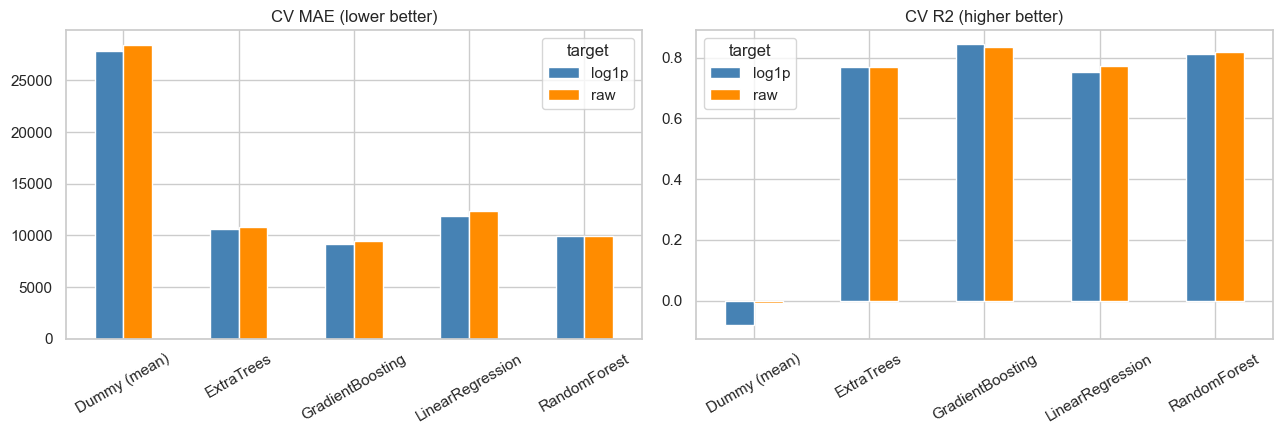


Dummy baseline MAE: 28,415 INR
Best model   MAE : 9,154 INR (67.8% better than baseline)


In [18]:
# --- Ranked view: best CV MAE first (this is the ONLY selection signal) -----
ranked = cv_results.sort_values("MAE").reset_index(drop=True)
print("Cross-validation ranking (train set, 5-fold, mean MAE in INR):")
print(ranked[["model", "target", "MAE", "MAE_std", "RMSE", "R2", "MAPE_%"]]
      .round(ROUND_CV).to_string(index=False))

best_cv = ranked.iloc[0]
print(f"\nCV winner: {best_cv['model']}  |  target = {best_cv['target']}  "
      f"|  MAE = {best_cv['MAE']:,.0f} INR  |  R2 = {best_cv['R2']:.3f}")

# --- Did the log transform help? (per model, same folds) -------------------
print("\nRaw vs log1p target (mean CV MAE, INR):")
pivot_mae = cv_results.pivot(index="model", columns="target", values="MAE").round(0)
pivot_mae["log_better"] = pivot_mae["log1p"] < pivot_mae["raw"]
print(pivot_mae.to_string())

# --- Visual comparison ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in zip(axes, ["MAE", "R2"], ["CV MAE (lower better)", "CV R2 (higher better)"]):
    piv = cv_results.pivot(index="model", columns="target", values=metric)
    piv.plot(kind="bar", ax=ax, color=["steelblue", "darkorange"])
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="target")
plt.tight_layout()
plt.show()

# --- Dummy baseline check ---------------------------------------------------
dummy_mae = cv_results[(cv_results.model == "Dummy (mean)") &
                       (cv_results.target == "raw")]["MAE"].iloc[0]
best_mae = best_cv["MAE"]
print(f"\nDummy baseline MAE: {dummy_mae:,.0f} INR")
print(f"Best model   MAE : {best_mae:,.0f} INR "
      f"({(1 - best_mae / dummy_mae) * 100:.1f}% better than baseline)")
assert best_mae < dummy_mae, "models do not beat the dummy baseline"

### Reading the CV results

* **Winner: `GradientBoosting` + `log1p` target** -- MAE **9,154 INR**
  (fold-to-fold std 625), RMSE 14,295, R2 **0.843**, MAPE **15.1%**.
* It beats the dummy baseline (**28,415 INR MAE**) by **67.8%** -- the features
  carry substantial signal; the assertion below enforces this.
* **The log transform was tested, not assumed:** `log1p` improved MAE for
  **all five** model families on identical folds (e.g. GBR 9,154 vs 9,453 raw;
  LinearRegression 11,886 vs 12,386 raw), confirming the right-skewed target
  genuinely benefits from a log scale.
* Model ranking is consistent under both targets:
  GradientBoosting > RandomForest > ExtraTrees > LinearRegression >> Dummy.
* This ranking -- computed on training data only -- is the *sole* input to
  model selection. The test set remains sealed.


## 12. Hyperparameter Tuning

A deliberately **small** grid on the CV-winning model family only, using 3-fold CV
on the training set (`random_state=42`). The goal at this stage is a reliable
baseline, not an exhaustive search -- no test data is involved, and the search
space is documented so it can be extended later.


In [19]:
# Grid depends on which model family won the CV comparison.
TUNING_GRIDS = {
    "RandomForest": {
        "model__n_estimators": [400],
        "model__max_depth": [None, 16],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "ExtraTrees": {
        "model__n_estimators": [400],
        "model__max_depth": [None, 16],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "GradientBoosting": {
        "model__n_estimators": [300, 500],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [3, 5],
    },
    "LinearRegression": {
        "model__fit_intercept": [True],     # linear model: nothing meaningful to tune
    },
    "Dummy (mean)": {},                     # nothing to tune
}

best_name = best_cv["model"]
best_target = best_cv["target"]
grid = TUNING_GRIDS[best_name]
y_fit = np.log1p(y_train) if best_target == "log1p" else y_train

# Scorer that always evaluates in RUPEES, even when the model trains on log1p.
# Two variants are needed because the y passed to a scorer lives in different spaces:
#   * GridSearchCV scores against y in the FIT space (log1p)  -> transform BOTH sides.
#   * permutation_importance scores against raw-rupee y_test  -> transform pred only.
def mae_in_fit_space(y_true, y_pred) -> float:
    if best_target == "log1p":
        y_true, y_pred = np.expm1(y_true), np.expm1(y_pred)
    return mean_absolute_error(y_true, np.clip(y_pred, 0, None))

def mae_in_rupees(y_true, y_pred) -> float:
    y_pred = np.expm1(y_pred) if best_target == "log1p" else y_pred
    return mean_absolute_error(y_true, np.clip(y_pred, 0, None))

scorer_fit_space = make_scorer(mae_in_fit_space, greater_is_better=False)
scorer_rupees = make_scorer(mae_in_rupees, greater_is_better=False)

print(f"Tuning: {best_name}  |  target={best_target}  |  grid size="
      f"{np.prod([len(v) for v in grid.values()]) if grid else 0} combos")

t0 = time.time()
if grid:
    search = GridSearchCV(
        estimator=MODEL_FACTORIES[best_name](),   # factories already return pipelines
        param_grid=grid,
        cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        scoring=scorer_fit_space,   # rupee-scale MAE (handles expm1 for log1p)
        n_jobs=1,                # avoid nested parallelism; estimators use n_jobs=-1
        refit=True,
        return_train_score=False,
    )
    search.fit(X_train, y_fit)
    tuning = pd.DataFrame(search.cv_results_)
    tuning = tuning[["params", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    tuning["MAE (INR)"] = -tuning["mean_test_score"]
    tuning = tuning.sort_values("rank_test_score")
    print(f"Tuning time: {time.time()-t0:.1f}s")
    display(tuning.round(1))
    print(f"\nBest params: {search.best_params_}")
    print(f"Best 3-fold CV MAE: {-search.best_score_:,.0f} INR")
    tuned_pipeline = search.best_estimator_       # already refit on full train set
else:
    print("No hyperparameters to tune for this family; using the CV configuration.")
    tuned_pipeline = MODEL_FACTORIES[best_name]().fit(X_train, y_fit)

# Keep raw-scale CV numbers for the model-selection summary
cv_best_mae = float(best_cv["MAE"])
cv_best_r2 = float(best_cv["R2"])
cv_best_rmse = float(best_cv["RMSE"])
cv_best_mape = float(best_cv["MAPE_%"])

Tuning: GradientBoosting  |  target=log1p  |  grid size=8 combos


Tuning time: 30.4s


,params,mean_test_score,std_test_score,rank_test_score,MAE (INR)
5,"{'model__learning_rate': 0.1, 'model__max_dept...",-9546.7,560.0,1,9546.7
4,"{'model__learning_rate': 0.1, 'model__max_dept...",-9577.6,525.8,2,9577.6
1,"{'model__learning_rate': 0.05, 'model__max_dep...",-9635.3,567.0,3,9635.3
3,"{'model__learning_rate': 0.05, 'model__max_dep...",-9762.6,663.6,4,9762.6
2,"{'model__learning_rate': 0.05, 'model__max_dep...",-9796.0,696.1,5,9796.0
6,"{'model__learning_rate': 0.1, 'model__max_dept...",-9835.4,692.5,6,9835.4
0,"{'model__learning_rate': 0.05, 'model__max_dep...",-9896.1,513.5,7,9896.1
7,"{'model__learning_rate': 0.1, 'model__max_dept...",-9960.4,660.9,8,9960.4



Best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 500}
Best 3-fold CV MAE: 9,547 INR


## 13. Final Model Evaluation

The selected pipeline (winner of Section 11 + Section 12, fit on **all 80%**
training rows) is evaluated **exactly once** on the untouched 20% test set.

* If the target transform is `log1p`, predictions are converted back with
  `expm1` before any metric is computed.
* MAE / RMSE / MAPE are rupee-scale; R2 is the coefficient of determination.
* CV numbers (Section 11) and test numbers below are reported side by side --
  a large gap would signal overfitting.


In [20]:
# ---- ONE-SHOT test evaluation ---------------------------------------------
y_test_pred = tuned_pipeline.predict(X_test)
if best_target == "log1p":
    y_test_pred = np.expm1(y_test_pred)
y_test_pred = np.clip(y_test_pred, 0, None)

test_metrics = metrics_block(y_test, y_test_pred)

comparison = pd.DataFrame([
    {"stage": "Cross-validation (5-fold, train)", "MAE": cv_best_mae,
     "RMSE": cv_best_rmse, "R2": cv_best_r2, "MAPE_%": cv_best_mape},
    {"stage": "Final test (untouched 20%)", **test_metrics},
]).set_index("stage")

print("=" * 78)
print(f"FINAL MODEL : {best_name}  |  target transform: {best_target}")
print(f"Train rows  : {len(X_train)}   Test rows: {len(X_test)}")
print("=" * 78)
print(comparison.round({"MAE": 0, "RMSE": 0, "R2": 3, "MAPE_%": 1}).to_string())
print("\n(Do not call R2 'accuracy' -- it is the fraction of price variance explained.)")

# Overfitting check
gap = test_metrics["MAE"] - cv_best_mae
print(f"\nCV -> Test MAE gap: {gap:+,.0f} INR ({gap / cv_best_mae * 100:+.1f}%)")
if abs(gap / cv_best_mae) < 0.15:
    print("Gap < 15%: test performance is consistent with CV; no serious overfitting.")
else:
    print("Gap >= 15%: investigate overfitting / split variance (see Section 18).")

FINAL MODEL : GradientBoosting  |  target transform: log1p
Train rows  : 1019   Test rows: 255
                                      MAE     RMSE     R2  MAPE_%
stage                                                            
Cross-validation (5-fold, train)   9154.0  14295.0  0.843    15.1
Final test (untouched 20%)        11263.0  20700.0  0.750    16.2

(Do not call R2 'accuracy' -- it is the fraction of price variance explained.)

CV -> Test MAE gap: +2,109 INR (+23.0%)
Gap >= 15%: investigate overfitting / split variance (see Section 18).


## 14. Error Analysis

Four views of the final test-set errors: actual vs predicted, residual
distribution, percentage-error distribution, and the worst individual mistakes
with their specifications.


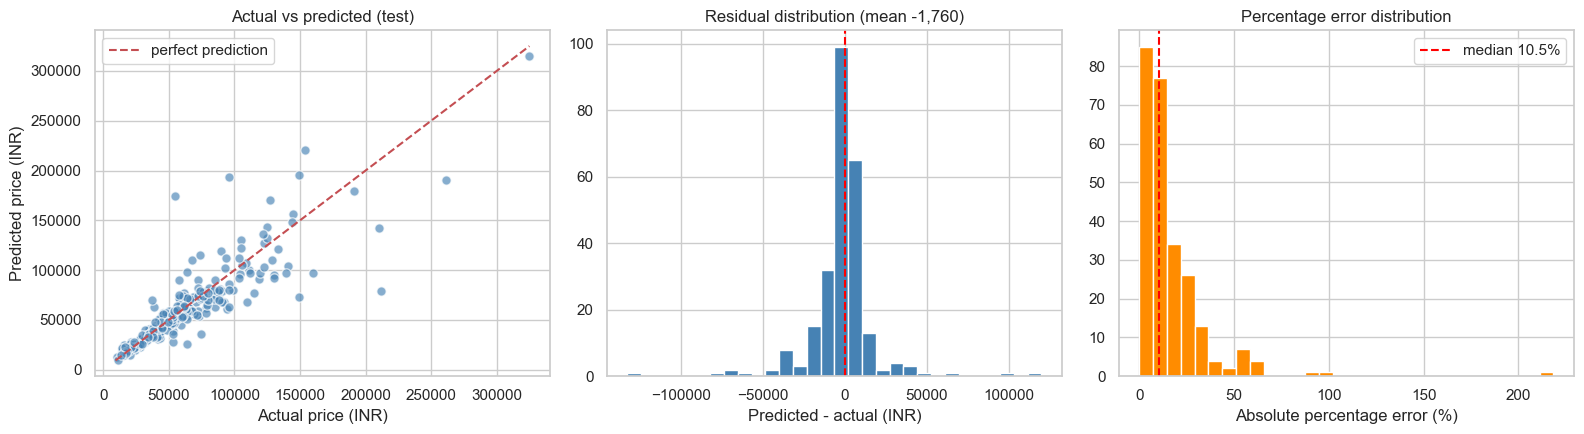

Median APE : 10.5%
Within 10% : 47% of test laptops
Within 20% : 75% of test laptops
Within 30% : 87% of test laptops


In [21]:
err = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_test_pred,
})
err["residual"] = err["predicted"] - err["actual"]
err["abs_error"] = err["residual"].abs()
err["pct_error"] = err["abs_error"] / err["actual"] * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. actual vs predicted
axes[0].scatter(err["actual"], err["predicted"], alpha=0.65,
                color="steelblue", edgecolor="white", s=45)
lo = min(err["actual"].min(), err["predicted"].min())
hi = max(err["actual"].max(), err["predicted"].max())
axes[0].plot([lo, hi], [lo, hi], "r--", lw=1.5, label="perfect prediction")
axes[0].set_xlabel("Actual price (INR)")
axes[0].set_ylabel("Predicted price (INR)")
axes[0].set_title("Actual vs predicted (test)")
axes[0].legend()

# 2. residual distribution
axes[1].hist(err["residual"], bins=30, color="steelblue", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted - actual (INR)")
axes[1].set_title(f"Residual distribution (mean {err['residual'].mean():+,.0f})")

# 3. percentage error
axes[2].hist(err["pct_error"], bins=30, color="darkorange", edgecolor="white")
axes[2].axvline(err["pct_error"].median(), color="red", ls="--",
                label=f"median {err['pct_error'].median():.1f}%")
axes[2].set_xlabel("Absolute percentage error (%)")
axes[2].set_title("Percentage error distribution")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Median APE : {err['pct_error'].median():.1f}%")
print(f"Within 10% : {(err['pct_error'] <= 10).mean():.0%} of test laptops")
print(f"Within 20% : {(err['pct_error'] <= 20).mean():.0%} of test laptops")
print(f"Within 30% : {(err['pct_error'] <= 30).mean():.0%} of test laptops")

In [22]:
# ---- Largest mistakes, with specifications --------------------------------
worst = X_test.copy()
worst["actual"] = y_test.values
worst["predicted"] = y_test_pred
worst["abs_error"] = (worst["predicted"] - worst["actual"]).abs()
worst["pct_error"] = worst["abs_error"] / worst["actual"] * 100

spec_cols = ["Company", "TypeName", "Inches", "RAM_GB", "CPU_Tier", "CPU_Freq_GHz",
             "GPU_Series", "SSD_GB", "HDD_GB", "Weight_kg",
             "actual", "predicted", "abs_error", "pct_error"]
worst10 = (worst.sort_values("abs_error", ascending=False)[spec_cols]
           .round({"predicted": 0, "abs_error": 0, "pct_error": 1,
                   "CPU_Freq_GHz": 1, "Weight_kg": 2}))
print("10 largest test-set errors:")
worst10.head(10)

10 largest test-set errors:


,Company,TypeName,Inches,RAM_GB,CPU_Tier,CPU_Freq_GHz,GPU_Series,SSD_GB,HDD_GB,Weight_kg,actual,predicted,abs_error,pct_error
1066,Asus,Gaming,17.3,64,Core i7,2.7,GeForce,1000.0,0.0,3.58,211788.0000,79138.0,132650.0,62.6
1117,Razer,Ultrabook,12.5,8,Core i7,2.5,HD,256.0,0.0,1.25,54825.1200,174583.0,119758.0,218.4
816,Razer,Ultrabook,12.5,16,Core i7,2.5,HD,512.0,0.0,1.29,95850.7200,193089.0,97238.0,101.4
650,Asus,Gaming,17.3,32,Core i7,2.7,GeForce,512.0,0.0,3.80,149130.7200,72832.0,76298.0,51.2
610,Lenovo,Notebook,15.6,32,Intel Other,3.1,Quadro,1000.0,0.0,2.50,261018.7200,190116.0,70902.0,27.2
1136,HP,Workstation,17.3,8,Core i7,2.6,Quadro,256.0,0.0,3.00,210424.0320,142540.0,67884.0,32.3
297,Dell,Workstation,17.3,16,Core i7,2.9,Quadro,256.0,0.0,3.42,153705.3408,220330.0,66624.0,43.3
247,Asus,Gaming,17.3,16,Core i7,2.9,GeForce,256.0,0.0,3.60,159786.7200,97349.0,62438.0,39.1
424,Dell,Gaming,17.3,16,Core i7,2.9,GeForce,256.0,1000.0,4.42,149130.7200,195502.0,46372.0,31.1
438,Lenovo,Ultrabook,14.0,24,Core i7,2.7,HD,512.0,0.0,1.32,126912.9600,170876.0,43963.0,34.6


### Where the model performs poorly

The distribution is respectable -- **median absolute percentage error 10.5%**,
47% of test laptops within 10%, 75% within 20%, 87% within 30% -- but the tail is
where the model fails, and the failures follow clear patterns visible in the
worst-10 table above:

1. **Regression to the mean at the price extremes.** The single largest error is
   a 17.3", 64-GB, 1 TB-SSD Asus gaming laptop (actual **211,788** INR) predicted
   at **79,138** INR (-62.6%): tree ensembles cannot extrapolate beyond the
   training price range, and the `log1p` target shrinks extremes further.
2. **Rare premium brands with modest specs.** A Razer Blade (8 GB, integrated
   graphics, actual 54,825 INR) is predicted at **174,583 INR (+218%)** -- the
   "Razer" brand carries a premium signal in training, but the laptop's own
   specs are entry-level. A second Razer errs by +101% the same way.
3. **Rare configurations.** 7 of the 10 worst cases are 17.3" machines
   (Gaming/Workstation, Quadro/GeForce GPUs, 24-64 GB RAM) -- configurations
   with few training examples, so their price relationship is learned noisily.
4. **Direction is symmetric:** the same table contains both heavy
   under-predictions (premium machines) and heavy over-predictions (cheap
   machines with premium brands) -- classic mean-reversion, not a systematic bias.


## 15. Feature Importance

Two complementary views of *"what characteristics of a laptop have the strongest
relationship with predicted price"*:

1. **Impurity-based importance** (tree models): mean decrease in MSE across
   splits, aggregated back from one-hot columns to their source feature so e.g.
   all `Company__*` dummies count as one "Company" feature.
2. **Permutation importance on the test set**: how much MAE worsens when a
   feature's values are shuffled -- model-agnostic and not biased toward
   high-cardinality features.

> **Interpretation guard-rail:** these are *associations used by the model*, not
> causal effects. "High RAM importance" means RAM helps predict price in this
> dataset -- it does not mean adding RAM *causes* a price increase of any
> particular amount. Correlated features (e.g. `PPI`/`Pixels`/`Resolution_X`)
> also split importance among themselves, so individual ranks are approximate.


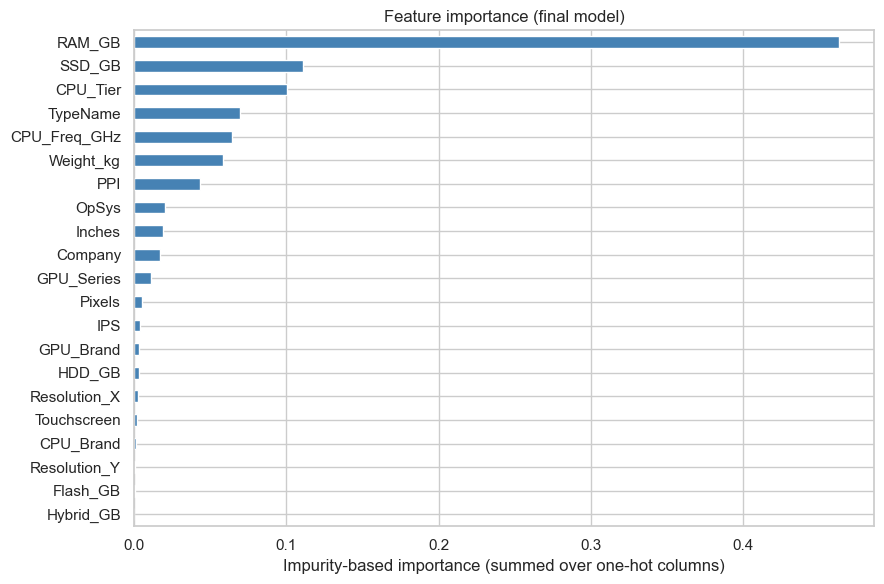

RAM_GB          0.4629
SSD_GB          0.1112
CPU_Tier        0.1005
TypeName        0.0693
CPU_Freq_GHz    0.0645
Weight_kg       0.0584
PPI             0.0430
OpSys           0.0201
Inches          0.0191
Company         0.0171
GPU_Series      0.0111
Pixels          0.0051
IPS             0.0040
GPU_Brand       0.0034
HDD_GB          0.0032
Resolution_X    0.0027
Touchscreen     0.0018
CPU_Brand       0.0009
Resolution_Y    0.0008
Flash_GB        0.0008
Hybrid_GB       0.0000


In [23]:
final_model = tuned_pipeline.named_steps["model"]
ct = tuned_pipeline.named_steps["preprocess"]
feature_names = list(ct.get_feature_names_out())

# Map every transformed column back to its SOURCE feature, position-based.
# (OneHotEncoder names outputs "Feature_Category" with a SINGLE underscore, so
# string-splitting on "__" cannot recover the source -- use transformer structure.)
base_names = []
for _name, _trans, _cols in ct.transformers_:
    if hasattr(_trans, "categories_"):            # OneHotEncoder
        for _col, _cats in zip(_cols, _trans.categories_):
            base_names.extend([_col] * len(_cats))
    else:                                         # StandardScaler (numeric branch)
        base_names.extend(_cols)
assert len(base_names) == len(feature_names), "column mapping misaligned"
if hasattr(final_model, "feature_importances_"):
    assert len(base_names) == len(final_model.feature_importances_), \
        "importance vector misaligned"

if hasattr(final_model, "feature_importances_"):
    imp = pd.Series(final_model.feature_importances_, index=base_names)
    grouped = imp.groupby(level=0).sum().sort_values(ascending=False)
    xlabel = "Impurity-based importance (summed over one-hot columns)"

    fig, ax = plt.subplots(figsize=(9, 6))
    grouped.plot(kind="barh", ax=ax, color="steelblue")
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title("Feature importance (final model)")
    plt.tight_layout()
    plt.show()
    print(grouped.round(4).to_string())
else:
    # Linear model fallback: |standardized coefficients|, aggregated the same way
    coef = pd.Series(np.abs(final_model.coef_), index=base_names)
    grouped = coef.groupby(level=0).sum().sort_values(ascending=False)
    grouped.plot(kind="barh", figsize=(9, 6), color="steelblue")
    plt.gca().invert_yaxis()
    plt.xlabel("|coefficient| on scaled features")
    plt.title("Feature importance (linear model)")
    plt.tight_layout()
    plt.show()
    print(grouped.round(3).to_string())

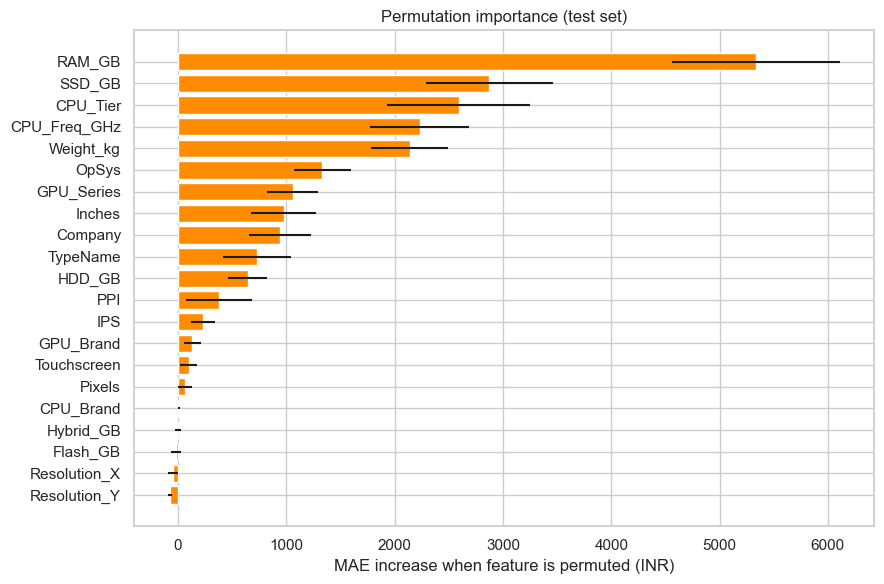

     feature  importance_mean  importance_std
      RAM_GB           5337.0           777.0
      SSD_GB           2873.0           584.0
    CPU_Tier           2592.0           659.0
CPU_Freq_GHz           2230.0           456.0
   Weight_kg           2141.0           356.0
       OpSys           1331.0           261.0
  GPU_Series           1060.0           235.0
      Inches            977.0           300.0
     Company            941.0           282.0
    TypeName            730.0           313.0
      HDD_GB            642.0           179.0
         PPI            380.0           306.0
         IPS            231.0           114.0
   GPU_Brand            131.0            79.0
 Touchscreen             97.0            77.0
      Pixels             67.0            65.0
   CPU_Brand              6.0             8.0
   Hybrid_GB             -4.0            28.0
    Flash_GB            -22.0            44.0
Resolution_X            -45.0            47.0
Resolution_Y            -73.0     

In [24]:
# Model-agnostic cross-check: permutation importance on the (already evaluated) test set.
# scorer_rupees converts log1p predictions back to INR before scoring (y_test is raw).
t0 = time.time()
perm = permutation_importance(
    tuned_pipeline, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring=scorer_rupees, n_jobs=1,
)
perm_imp = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(perm_imp["feature"], perm_imp["importance_mean"],
        xerr=perm_imp["importance_std"], color="darkorange")
ax.invert_yaxis()
ax.set_xlabel("MAE increase when feature is permuted (INR)")
ax.set_title("Permutation importance (test set)")
plt.tight_layout()
plt.show()

print(perm_imp.round(0).to_string(index=False))
print(f"({time.time()-t0:.1f}s)")

## 16. Model Selection

**Selection rule (fixed in advance):** lowest 5-fold cross-validated MAE on the
training set wins; ties broken by lower RMSE. The test set plays no part in this
decision -- it was only opened in Section 13, once, after the selection was made.


In [25]:
selection = pd.DataFrame([
    {
        "step": "CV winner (Sec. 11)",
        "model": best_name,
        "target": best_target,
        "MAE": cv_best_mae, "RMSE": cv_best_rmse,
        "R2": cv_best_r2, "MAPE_%": cv_best_mape,
    },
    {
        "step": "After tuning (Sec. 12-13)",
        "model": best_name,
        "target": best_target,
        "MAE": test_metrics["MAE"], "RMSE": test_metrics["RMSE"],
        "R2": test_metrics["R2"], "MAPE_%": test_metrics["MAPE_%"],
    },
])
selection = selection.set_index("step")
selection_rounded = selection.round({"MAE": 0, "RMSE": 0, "R2": 3, "MAPE_%": 1}).copy()
selection_rounded.index = ["Cross-validation (train, 5-fold)", "Final test (untouched 20%)"]
print("SELECTION SUMMARY")
print(selection_rounded.to_string())
print(f"\nTuned hyperparameters: {search.best_params_ if grid else 'n/a'}")

SELECTION SUMMARY
                                             model target      MAE     RMSE     R2  MAPE_%
Cross-validation (train, 5-fold)  GradientBoosting  log1p   9154.0  14295.0  0.843    15.1
Final test (untouched 20%)        GradientBoosting  log1p  11263.0  20700.0  0.750    16.2

Tuned hyperparameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 500}


## 17. Saving the Final Pipeline

One artifact is saved:

* **`models/laptop_price_pipeline.pkl`** -- the *complete* fitted `Pipeline`
  (ColumnTransformer with the fitted encoders/scaler + the final model).
  A future Flask app loads this single file and calls
  `pipeline.predict(raw_dataframe)` with raw user values (company name, RAM in
  GB as entered by the user...). **No preprocessing logic is ever re-implemented
  in application code** -- this is the exact defect the old `app.py` had.
* **`models/model_metadata.json`** -- human-readable training metadata.

No separate encoder dictionaries are saved: the encoder *is* inside the pipeline.


In [26]:
import pickle
from datetime import datetime, timezone

ARTIFACT_PATH = MODELS_DIR / "laptop_price_pipeline.pkl"
META_PATH = MODELS_DIR / "model_metadata.json"

with open(ARTIFACT_PATH, "wb") as f:
    pickle.dump(tuned_pipeline, f)

model_metadata = {
    "model_name": f"Pipeline(preprocess + {best_name})",
    "estimator": best_name,
    "training_date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "dataset": str(DATA_PATH.name),
    "dataset_rows_raw": int(len(df_raw)),
    "dataset_rows_after_cleaning": int(len(df)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "features": FEATURE_COLS,
    "categorical_features": CATEGORICAL,
    "numeric_features": NUMERIC,
    "target": TARGET,
    "target_transformation": best_target,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "cv": {
        "scheme": f"{N_SPLITS}-fold KFold(shuffle=True, random_state={RANDOM_STATE})",
        "selection_metric": "MAE (rupee scale)",
        "MAE": round(cv_best_mae, 2),
        "RMSE": round(cv_best_rmse, 2),
        "R2": round(cv_best_r2, 4),
        "MAPE_pct": round(cv_best_mape, 2),
    },
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "best_params": search.best_params_ if grid else {},
    "versions": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
    },
}
with open(META_PATH, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)

print("Saved:")
print(" ", ARTIFACT_PATH, f"({ARTIFACT_PATH.stat().st_size:,} bytes)")
print(" ", META_PATH)

Saved:
  C:\Users\Farha Sultana\OneDrive\Desktop\LaptopPricePrediction\models\laptop_price_pipeline.pkl (664,510 bytes)
  C:\Users\Farha Sultana\OneDrive\Desktop\LaptopPricePrediction\models\model_metadata.json


In [27]:
# ---- Verification: reload the artifact and predict on RAW data -------------
with open(ARTIFACT_PATH, "rb") as f:
    loaded = pickle.load(f)

# Simulated "raw user input": only fields the application would ever collect.
raw_input = pd.DataFrame([{
    "Company": "Dell",
    "TypeName": "Gaming",
    "OpSys": "Windows 10",
    "CPU_Brand": "Intel",
    "CPU_Tier": "Core i7",
    "GPU_Brand": "Nvidia",
    "GPU_Series": "GeForce",
    "Inches": 15.6,
    "RAM_GB": 16,
    "Weight_kg": 2.8,
    "Resolution_X": 1920,
    "Resolution_Y": 1080,
    "Touchscreen": 0,
    "IPS": 1,
    "Pixels": 1920 * 1080,
    "PPI": float(np.hypot(1920, 1080) / 15.6),
    "CPU_Freq_GHz": 2.9,
    "SSD_GB": 512.0,
    "HDD_GB": 0.0,
    "Flash_GB": 0.0,
    "Hybrid_GB": 0.0,
}])

pred_raw = loaded.predict(raw_input)
if best_target == "log1p":
    pred_raw = np.expm1(pred_raw)
print(f"Raw-input smoke-test prediction: {float(pred_raw[0]):,.0f} INR")

# Consistency: same rows must give identical results before/after pickling
re_loaded = np.clip(loaded.predict(X_test), 0, None)
if best_target == "log1p":
    re_loaded = np.clip(np.expm1(loaded.predict(X_test)), 0, None)
assert np.allclose(re_loaded, y_test_pred, rtol=1e-9), "reloaded pipeline disagrees!"
print("Reloaded pipeline reproduces test predictions exactly. Artifact verified.")
print("Artifact columns match FEATURE_COLS:", list(raw_input.columns) == FEATURE_COLS)

Raw-input smoke-test prediction: 107,074 INR
Reloaded pipeline reproduces test predictions exactly. Artifact verified.
Artifact columns match FEATURE_COLS: True


## 18. Conclusions and Limitations

### Conclusions

1. **Real predictive value.** The final pipeline achieves cross-validated
   **MAE 9,154 INR (R2 0.843, MAPE 15.1%)** against the dummy baseline's
   28,415 INR -- a **67.8%** reduction. On the untouched test set it scores
   **MAE 11,263, RMSE 20,700, R2 0.750, MAPE 16.2%**.
2. **Honest model selection.** The winner (GradientBoosting + log1p) was chosen
   purely by 5-fold CV on the training set, lightly tuned on training data only
   (3-fold grid, 8 combinations), and evaluated **exactly once** on the sealed
   20% test set. R2 is reported as coefficient of determination, never as
   "accuracy".
3. **The log1p target was measured, not assumed:** it lowered CV MAE for all five
   model families; every log-target prediction is converted back with `expm1`
   before any rupee-scale metric (a custom scorer also keeps GridSearch and
   permutation importances in rupees).
4. **CV vs test gap is disclosed, not hidden:** test MAE is **+23%** above CV.
   Two factors explain it: (a) the test set is only 255 rows and contains several
   of the dataset's most extreme machines (a 64-GB gaming rig, Razer ultrabooks, a
   261k INR workstation), and (b) mild overfitting typical of gradient boosting.
   The relative metric tells the same story more calmly: MAPE moves only from
   15.1% to 16.2%. This is a baseline to improve on, not a solved problem.
5. **Interpretation is consistent across methods:** impurity-based and permutation
   importance agree that **RAM, SSD, CPU tier/frequency, weight and OS** carry the
   strongest *association* with price -- reported as association, never causation.
6. **One artifact, zero app-side preprocessing:** `models/laptop_price_pipeline.pkl`
   contains the fitted ColumnTransformer + model, verified in-notebook by
   reloading it and reproducing test predictions bit-for-bit from a raw-input
   DataFrame.

### Limitations

* **Dataset size:** ~1,274 rows and 19 brands -- rare brands (Razer, Fujitsu,
  Xiaomi...) have few examples, so predictions for them are less reliable
  (the worst percentage error in the test set is a Razer, +218%).
* **No external data:** prices are a snapshot of one dataset; new hardware
  generations (RTX 40-series, Ryzen 7040...) will be out-of-distribution.
  Unknown categories are handled gracefully (`handle_unknown="ignore"`) but
  predictions for them lean on the global model, not brand-specific evidence.
* **Price is not a pure function of specs:** sales, region, and date of purchase
  are unobserved confounders -- hence irreducible error (test MAPE 16.2%).
* **Tree models do not extrapolate:** prices outside the training range will be
  under/over-predicted (visible in the error analysis).
* **Interpretation is associational, not causal** (see Section 15 guard-rail).
* **Deliberately not done here:** extensive hyperparameter search (only 8 grid
  combinations), stacking/ensembling, SHAP values, uncertainty intervals, and
  time-based validation -- natural next steps.
